# Judging estimators on the WNBA 2025 shots


One row is one shot. The outcome `made_flag` is 1 when the shot is made and 0 when it is missed. Everything below reads the frozen clean file `wnba_clean.csv` at the top of the repository, so from `topics/` the path is `../wnba_clean.csv`. Seed 651.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. The Fisher SE beside the bootstrap SE

The Fisher SE is $1/\sqrt{n\,I(\hat p)}$ with $I(p)=1/(p(1-p))$ for one shot. The bootstrap SE comes from resampling the data 2,000 times. I resample two ways: **shots** one at a time, and **whole players** at a time.

In [2]:
df = pd.read_csv("../wnba_clean.csv")
y = df["made_flag"].to_numpy()
n, p_hat = len(y), y.mean()
info = 1 / (p_hat * (1 - p_hat))
se_fisher = 1 / np.sqrt(n * info)
rng = np.random.default_rng(651)
boot = [rng.choice(y, n).mean() for _ in range(2000)]
g = df.groupby("player_id")["made_flag"]
g = g.agg(["sum", "count"]).to_numpy()
pick = rng.integers(0, len(g), (2000, len(g)))
boot_p = g[pick, 0].sum(1) / g[pick, 1].sum(1)
print("Fisher SE", round(se_fisher, 4))
print("boot, shots", round(np.std(boot, ddof=1), 4))
print("boot, players", round(boot_p.std(ddof=1), 4))

Fisher SE 0.0025
boot, shots 0.0025
boot, players 0.0055


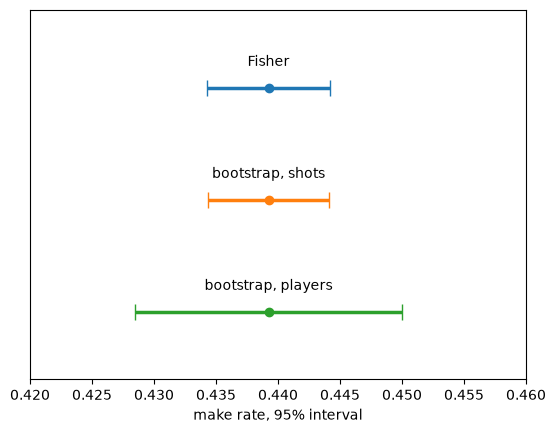

In [3]:
se_boot, se_boot_p = np.std(boot, ddof=1), np.std(boot_p, ddof=1)
rows = [("Fisher", p_hat, se_fisher), ("bootstrap, shots", p_hat, se_boot), ("bootstrap, players", p_hat, se_boot_p)]
for i, (label, mid, s) in enumerate(rows):
    plt.errorbar(mid, 2 - i, xerr=1.96 * s, fmt="o", capsize=6, lw=2.5)
    plt.text(mid, 2 - i + 0.2, label, ha="center")
plt.ylim(-0.6, 2.7); plt.yticks([]); plt.xlim(0.42, 0.46)
plt.xlabel("make rate, 95% interval"); plt.show()

## 2. Subsamples of size 5: the divide-by-n variance runs low

I draw 20,000 random subsamples of 5 shots. For each I compute the variance two ways and average. The true variance is computed on all the shots.

In [4]:
rng = np.random.default_rng(651)
for col in ("shot_distance", "made_flag"):
    x = df[col].to_numpy(float)
    truth = x.var()
    subs = np.array([rng.choice(x, 5, replace=False)
                     for _ in range(20000)])
    v_n = subs.var(axis=1, ddof=0).mean()
    v_n1 = subs.var(axis=1, ddof=1).mean()
    print(col, round(v_n / truth, 2),
          round(v_n1 / truth, 2))

shot_distance 0.8 1.0
made_flag 0.8 1.0


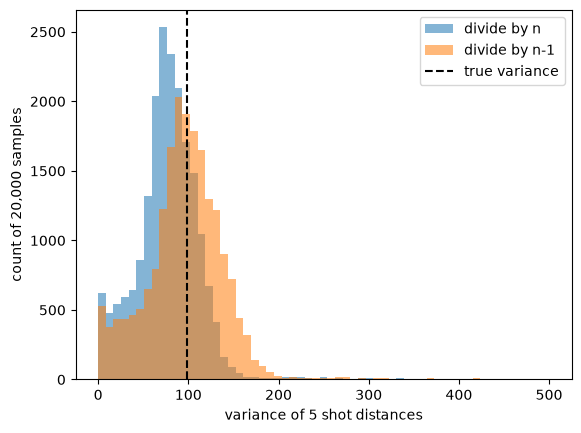

In [5]:
x = df["shot_distance"].to_numpy(float)
rng = np.random.default_rng(651)
subs_d = np.array([rng.choice(x, size=5, replace=False) for _ in range(20000)])
for ddof, label in ((0, "divide by n"), (1, "divide by n-1")):
    plt.hist(subs_d.var(axis=1, ddof=ddof), bins=np.linspace(0, 500, 60), alpha=0.55, label=label)
plt.axvline(x.var(), ls="--", color="k", label="true variance")
plt.xlabel("variance of 5 shot distances"); plt.ylabel("count of 20,000 samples"); plt.legend(); plt.show()

## 3. Bias, variance and MSE of the two variance estimators

Same subsamples, shot distance only. For each estimator: bias, variance, and the MSE, which should equal bias squared plus variance.

In [6]:
x = df["shot_distance"].to_numpy(float)
truth = x.var()
rng = np.random.default_rng(651)
subs = np.array([rng.choice(x, 5, replace=False)
                 for _ in range(20000)])
print("by   bias   var   b2+var   MSE")
for name, d in (("n", 0), ("n-1", 1)):
    v = subs.var(axis=1, ddof=d)
    bias = v.mean() - truth
    var = v.var()
    mse = ((v - truth) ** 2).mean()
    print(name, round(bias, 1), round(var),
          round(bias**2 + var), round(mse))

by   bias   var   b2+var   MSE
n -19.6 2054 2439 2439
n-1 0.1 3210 3210 3210


In [7]:
res = {}
for name, ddof in (("n", 0), ("n-1", 1)):
    v = subs.var(axis=1, ddof=ddof)
    res[name] = ((v.mean() - truth), v.var())
bias_n, var_n = res["n"]
bias_n1, var_n1 = res["n-1"]

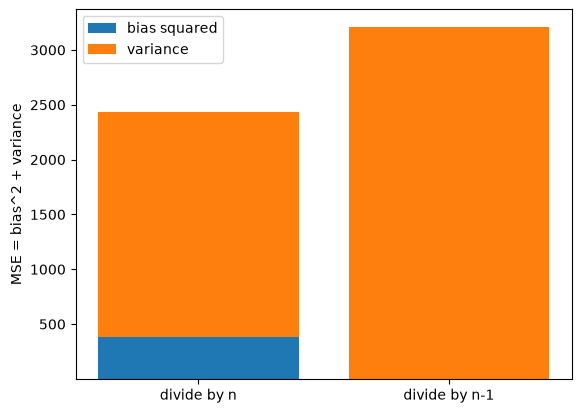

In [8]:
labels = ["divide by n", "divide by n-1"]
bias2 = [bias_n**2, bias_n1**2]
var_ = [var_n, var_n1]
plt.bar(labels, bias2, label="bias squared")
plt.bar(labels, var_, bottom=bias2, label="variance")
plt.ylabel("MSE = bias^2 + variance"); plt.legend(); plt.show()

## AI Note

I used Claude (Anthropic) to help me write and check this code. I ran every cell on my laptop and can explain every line. The words on the slides (Judging Estimators Presentation) and any interpretation of values are my own.